# 03 – Veri Analizi

Bu notebook ödevin **3. Veri Analizi** maddesini kapsar: sınıf dağılımı ve dengesizlik analizi, grafiksel analiz ve SMOTE ile dengeleme denemesi.

Analizler yalnızca **train verisi** üzerinde yapılır, test verisine dokunulmaz. Korelasyon ısı haritası ve özellik bazlı grafikler `01_veri_tanitimi_eda` notebook'unda temiz veri üzerinde çizilmiştir.

Girdi: `outputs/X_train.csv`, `outputs/y_train.csv` (02'nin çıktısı)

## 1. Kurulum

SMOTE için `imbalanced-learn` paketi gerekir. Kurulu değilse aşağıdaki satırın başındaki `#` işaretini kaldırıp bir kez çalıştırın, ardından kernel'i yeniden başlatın.

In [1]:
# %pip install imbalanced-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

os.makedirs("outputs/figures", exist_ok=True)

def grafik_kaydet(ad):
    # O anki grafiği rapor için PNG olarak kaydeder
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Verinin yüklenmesi

In [2]:
X_train = pd.read_csv("outputs/X_train.csv")
y_train = pd.read_csv("outputs/y_train.csv").squeeze()   # tek sütunlu tabloyu Series'e çevirir

etiket = {-1: "Phishing", 1: "Normal"}
renk = {"Phishing": "#d9534f", "Normal": "#5cb85c"}

print("Train:", X_train.shape)

Train: (4617, 31)


## 3. Sınıf dağılımı ve dengesizlik

Dengesizlik oranı, çoğunluk sınıfının azınlık sınıfına oranıdır. 1'e yakın değerler dengeli veriyi gösterir.

          adet  oran (%)
result                  
Phishing  2377     51.48
Normal    2240     48.52
Dengesizlik oranı (çoğunluk / azınlık): 1.06


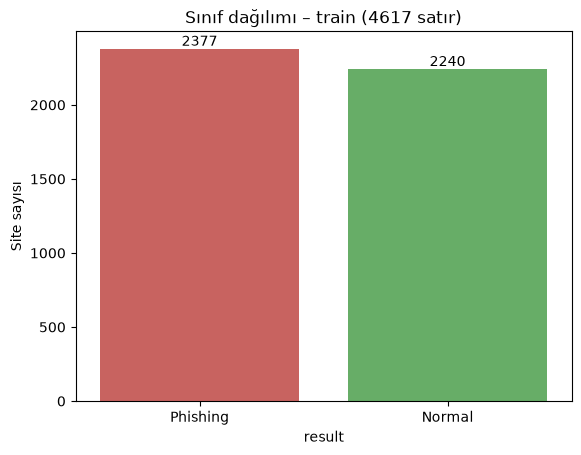

In [3]:
sinif = y_train.map(etiket).value_counts().reindex(["Phishing", "Normal"])
print(pd.DataFrame({"adet": sinif, "oran (%)": (sinif / len(y_train) * 100).round(2)}))
print("Dengesizlik oranı (çoğunluk / azınlık):", round(sinif.max() / sinif.min(), 2))

ax = sns.barplot(x=sinif.index, y=sinif.values, hue=sinif.index, palette=renk, legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title(f"Sınıf dağılımı – train ({len(y_train)} satır)")
plt.ylabel("Site sayısı")
grafik_kaydet("sinif_dagilimi_train")
plt.show()

## 4. Grafiksel analiz

### 4.1 Histogram

02'de türetilen özelliklerin sınıflara göre dağılımı. İki sınıfın dağılımları birbirinden ne kadar ayrıksa özellik o kadar ayırt edicidir.

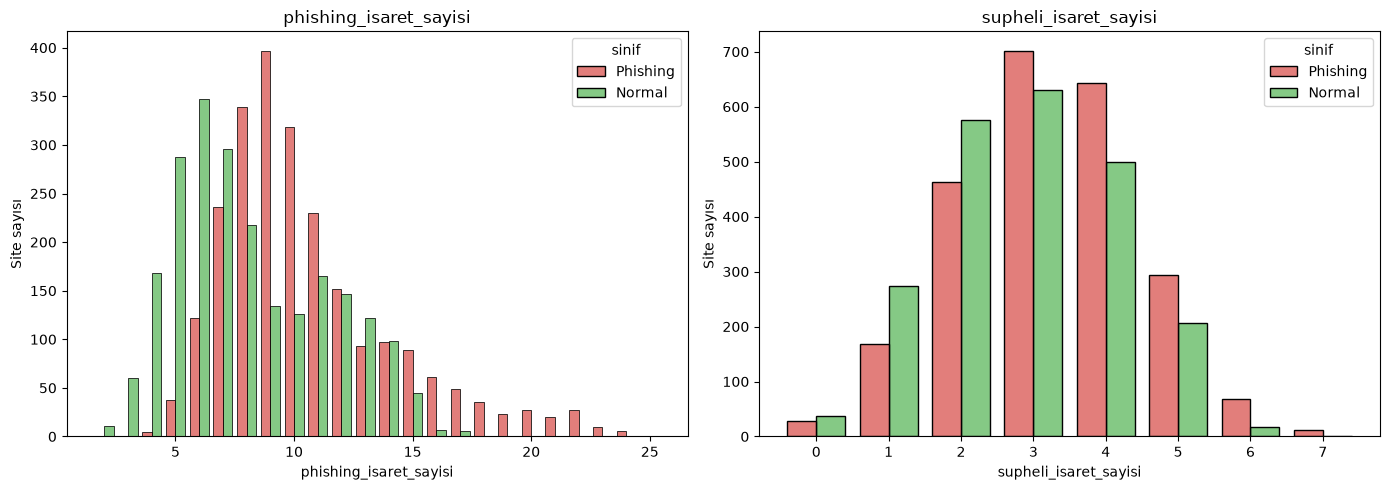

In [4]:
veri = X_train.assign(sinif=y_train.map(etiket))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["phishing_isaret_sayisi", "supheli_isaret_sayisi"]):
    sns.histplot(data=veri, x=col, hue="sinif", palette=renk, discrete=True,
                 multiple="dodge", shrink=0.8, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Site sayısı")
plt.tight_layout()
grafik_kaydet("histogram_turetilen_ozellikler")
plt.show()

### 4.2 Scatter plot (PCA)

31 özellik, PCA ile 2 boyuta indirgenerek sınıfların ne kadar ayrıştığı görselleştirilir. PCA öncesinde özellikler standartlaştırılır, çünkü PCA ölçeğe duyarlıdır.

Açıklanan varyans oranı: [0.177 0.125] toplam: 0.302


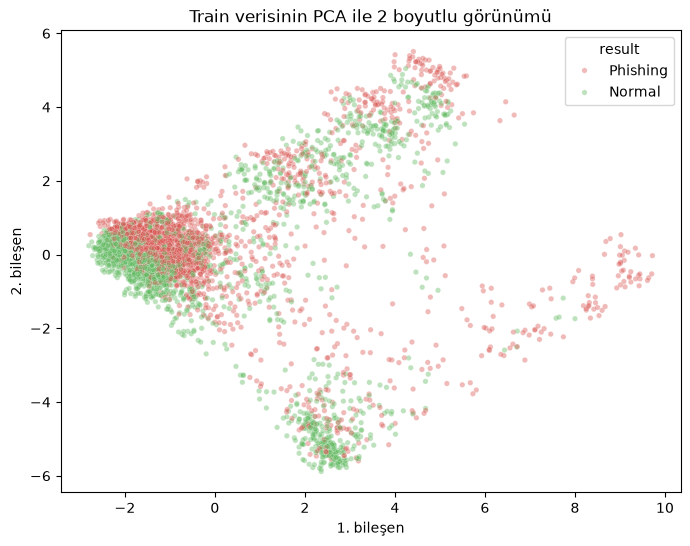

In [5]:
X_olcekli = StandardScaler().fit_transform(X_train)
pca = PCA(n_components=2, random_state=42)
bilesenler = pca.fit_transform(X_olcekli)
print("Açıklanan varyans oranı:", pca.explained_variance_ratio_.round(3),
      "toplam:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=bilesenler[:, 0], y=bilesenler[:, 1], hue=y_train.map(etiket),
                palette=renk, alpha=0.4, s=15)
plt.xlabel("1. bileşen")
plt.ylabel("2. bileşen")
plt.title("Train verisinin PCA ile 2 boyutlu görünümü")
grafik_kaydet("pca_scatter")
plt.show()

## 5. SMOTE ile veri dengeleme

**SMOTE** (Synthetic Minority Over-sampling Technique), azınlık sınıfındaki bir örnek ile en yakın komşularından biri arasında rastgele bir nokta seçerek sentetik örnekler üretir. Böylece azınlık sınıfının örnek sayısı çoğunluk sınıfına eşitlenir.

### 5.1 SMOTE sonrası sınıf dağılımı

          SMOTE öncesi  SMOTE sonrası
result                               
Phishing          2377           2377
Normal            2240           2377
Üretilen sentetik satır: 137, ondalıklı değer içeren: 0


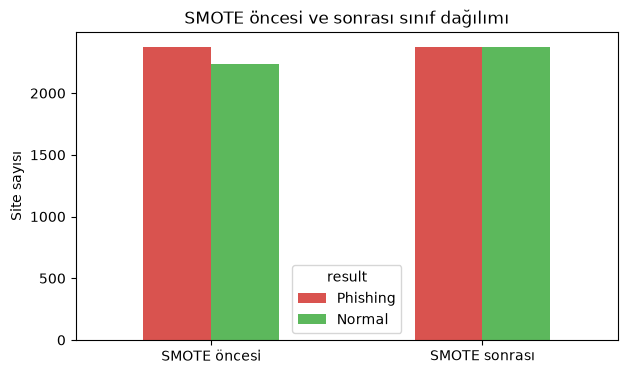

In [6]:
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

once = y_train.map(etiket).value_counts().reindex(["Phishing", "Normal"])
sonra = y_smote.map(etiket).value_counts().reindex(["Phishing", "Normal"])
print(pd.DataFrame({"SMOTE öncesi": once, "SMOTE sonrası": sonra}))

# SMOTE iki örnek arasında ara değer üretir; özellikler -1/0/1 olduğu için ondalıklı değerler oluşur
sentetik = X_smote.iloc[len(X_train):]
ondalikli = (sentetik % 1 != 0).any(axis=1).sum()
print(f"Üretilen sentetik satır: {len(sentetik)}, ondalıklı değer içeren: {ondalikli}")

pd.DataFrame({"SMOTE öncesi": once, "SMOTE sonrası": sonra}).T.plot(
    kind="bar", color=[renk["Phishing"], renk["Normal"]], rot=0, figsize=(7, 4))
plt.ylabel("Site sayısı")
plt.title("SMOTE öncesi ve sonrası sınıf dağılımı")
grafik_kaydet("smote_oncesi_sonrasi")
plt.show()

Özellikler yalnızca -1, 0 ve 1 değerlerini alabildiği için SMOTE'un ürettiği ondalıklı değerler (ör. 0,37) gerçek bir siteye karşılık gelmez. Bu, SMOTE'un kategorik değerli bu veri setine tam uygun olmadığını gösterir.

### 5.2 SMOTE'lu ve SMOTE'suz karşılaştırma

SMOTE'un etkisi, bir ağaç tabanlı (Random Forest) ve bir doğrusal (Logistic Regression) model üzerinde 5 katlı CV ile ölçülür.

`imblearn` pipeline'ı SMOTE'u **yalnızca her CV katının eğitim kısmına** uygular. Validation parçası gerçek veri olarak kalır, böylece sentetik örnekler değerlendirmeye karışmaz.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skorlar = {
    "f1": make_scorer(f1_score, pos_label=-1),          # phishing = -1
    "recall": make_scorer(recall_score, pos_label=-1),
    "precision": make_scorer(precision_score, pos_label=-1),
    "accuracy": "accuracy",
}

denemeler = [
    ("Random Forest", False, make_pipeline(RandomForestClassifier(random_state=42, n_jobs=-1))),
    ("Random Forest", True, make_pipeline(SMOTE(random_state=42), RandomForestClassifier(random_state=42, n_jobs=-1))),
    ("Logistic Regression", False, make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ("Logistic Regression", True, make_pipeline(StandardScaler(), SMOTE(random_state=42), LogisticRegression(max_iter=1000))),
]

satirlar = []
for model_adi, smote_var, model in denemeler:
    sonuc = cross_validate(model, X_train, y_train, cv=cv, scoring=skorlar)
    satirlar.append({"model": model_adi, "smote": smote_var,
                     **{m: sonuc[f"test_{m}"].mean() for m in skorlar}})

smote_sonuc = pd.DataFrame(satirlar).round(4)
smote_sonuc.to_csv("outputs/smote_karsilastirma.csv", index=False)
smote_sonuc

,model,smote,f1,recall,precision,accuracy
0,Random Forest,False,0.9584,0.9541,0.9627,0.9573
1,Random Forest,True,0.9569,0.9533,0.9607,0.9558
2,Logistic Regression,False,0.9272,0.9230,0.9316,0.9253
3,Logistic Regression,True,0.9263,0.9192,0.9338,0.9246


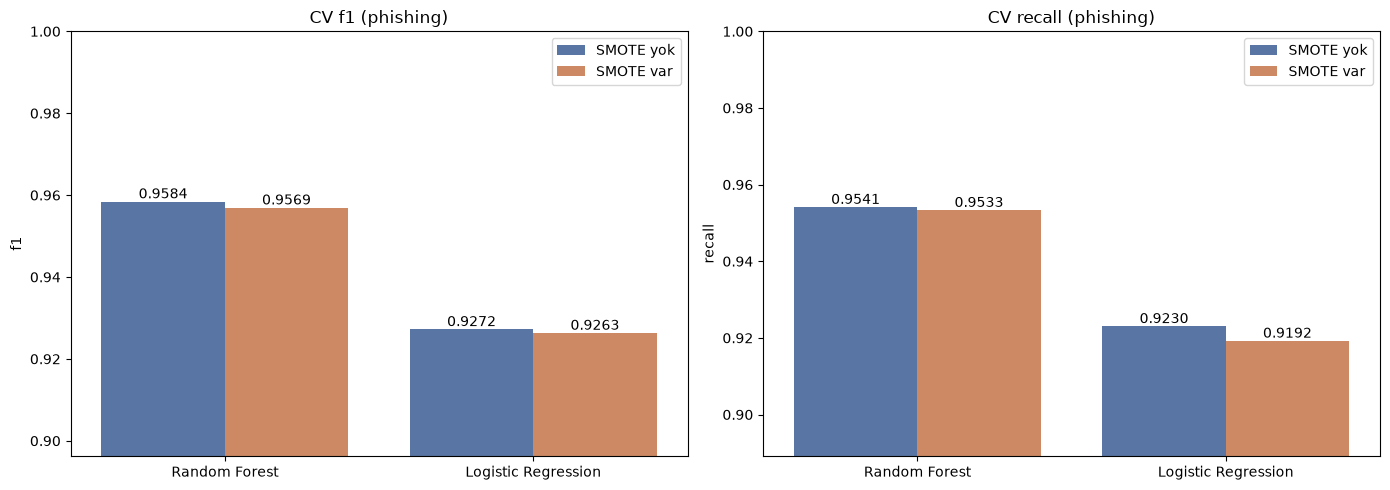

In [8]:
grafik = smote_sonuc.assign(deneme=smote_sonuc["smote"].map({False: "SMOTE yok", True: "SMOTE var"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrik in zip(axes, ["f1", "recall"]):
    sns.barplot(data=grafik, x="model", y=metrik, hue="deneme", ax=ax, palette=["#4c72b0", "#dd8452"])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.4f")
    ax.set_ylim(grafik[metrik].min() - 0.03, 1)   # farklar görünsün diye eksen 0'dan başlamıyor
    ax.set_title(f"CV {metrik} (phishing)")
    ax.set_xlabel("")
    ax.legend(title="")
plt.tight_layout()
grafik_kaydet("smote_karsilastirma")
plt.show()

In [9]:
# SMOTE'un F1 skoruna etkisi
fark = smote_sonuc.pivot(index="model", columns="smote", values="f1")
fark.columns = ["SMOTE yok", "SMOTE var"]
fark["fark"] = (fark["SMOTE var"] - fark["SMOTE yok"]).round(4)
fark

,SMOTE yok,SMOTE var,fark
model,,,
Logistic Regression,0.9272,0.9263,-0.0009
Random Forest,0.9584,0.9569,-0.0015


## 6. Sonuç

Train verisinde dengesizlik oranı 1'e çok yakın olduğu için veri dengeli kabul edilir. SMOTE'lu ve SMOTE'suz sonuçlar arasındaki fark ihmal edilebilir düzeydedir, ayrıca SMOTE bu veri setinde gerçekte var olmayan ondalıklı değerler üretmektedir. Bu nedenle **04 ve 05 notebook'larındaki modellerde SMOTE kullanılmayacaktır.**